# 03 · N-gram Language Models (Module II, plus text generation for Module V)

**Theory.** A language model assigns a probability to a sentence. By the chain rule,
P(w1..wm) = Π P(wi | w1..wi-1). An *n-gram* model makes the Markov assumption that only the previous
n−1 words matter, and estimates each factor by counting: P(w | h) = c(h,w) / c(h).
A larger n uses more context but sees each history less often (**sparsity**). Any n-gram never seen
in training gets probability 0, which makes the whole sentence probability 0. *Smoothing* (add-k,
Laplace) moves a little probability mass to unseen events. *Perplexity* = exp(−average log-prob per
word) measures how surprised the model is by held-out text; lower is better.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import math
import random
import time
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import FAST, SEED
from src.data import load
from src.ngram import NGramLM, sentences_from_text, BOS, UNK
from src.evaluate import save_results

pd.set_option("display.max_colwidth", 120)
K = 0.01  # add-k constant, fixed in advance (tuning it on the test set would be cheating)

## Data: BBC article bodies, 80/20 split by article
The split (column `lm_split`) is by *article*, so sentences from one story never appear in both
train and test.

In [2]:
bbc = load("bbc")
if FAST:
    bbc = bbc.groupby("lm_split").head(150)
train_sents = [s for body in bbc[bbc.lm_split == "train"].body for s in sentences_from_text(body)]
test_sents = [s for body in bbc[bbc.lm_split == "test"].body for s in sentences_from_text(body)]
print(f"train: {len(train_sents):,} sentences, {sum(map(len, train_sents)):,} words")
print(f"test:  {len(test_sents):,} sentences, {sum(map(len, test_sents)):,} words")
print("example:", train_sents[0])

train: 31,366 sentences, 642,011 words
test:  7,591 sentences, 158,473 words
example: ['gordon', 'brown', 'will', 'seek', 'to', 'put', 'the', 'economy', 'at', 'the', 'centre', 'of', "labour's", 'bid', 'for', 'a', 'third', 'term', 'in', 'power', 'when', 'he', 'delivers', 'his', 'ninth', 'budget', 'at', '1230', 'gmt']


## Train 9 models: n = 1, 2, 3 × smoothing = none, laplace, add-k (k = 0.01)
Words seen fewer than 2 times in training become `<UNK>`.

In [3]:
models = {}
t0 = time.perf_counter()
for n in [1, 2, 3]:
    base = NGramLM(n=n, smoothing="none").fit(train_sents)
    for sm in ["none", "laplace", "addk"]:
        # Counts do not depend on smoothing, so share them instead of refitting 3 times.
        lm = NGramLM(n=n, smoothing=sm, k=K)
        lm.vocab, lm.counts, lm.totals = base.vocab, base.counts, base.totals
        models[(n, sm)] = lm
print(f"trained in {time.perf_counter() - t0:.1f}s | vocabulary V = {len(base.vocab):,} "
      f"(incl. <UNK>, </s>)")
print({f"{n}-gram distinct histories": len(models[(n, 'none')].counts) for n in [1, 2, 3]})

trained in 1.4s | vocabulary V = 17,510 (incl. <UNK>, </s>)
{'1-gram distinct histories': 1, '2-gram distinct histories': 17510, '3-gram distinct histories': 245292}


## What the model has learned: the conditional distribution P(w | h)

In [4]:
def top_next(lm, history, k=6):
    dist = lm.distribution(tuple(history))
    return [(w, round(p, 3)) for w, p in sorted(dist.items(), key=lambda x: -x[1])[:k]]

print("unigram P(w)            :", top_next(models[(1, "none")], []))
print("bigram  P(w | prime)    :", top_next(models[(2, "none")], ["prime"]))
print("trigram P(w | the prime):", top_next(models[(3, "none")], ["the", "prime"]))
print("bigram  P(w | <s>)      :", top_next(models[(2, "none")], [BOS]))
for n in [1, 2, 3]:
    for sm in ["none", "laplace", "addk"]:
        h = {1: (), 2: ("prime",), 3: ("the", "prime")}[n]
        assert math.isclose(sum(models[(n, sm)].distribution(h).values()), 1.0)
print("each distribution sums to 1 ✓")

unigram P(w)            : [('the', 0.059), ('</s>', 0.047), ('to', 0.028), ('of', 0.022), ('and', 0.021), ('a', 0.021)]
bigram  P(w | prime)    : [('minister', 0.862), ("minister's", 0.098), ('ministers', 0.02), ('time', 0.012), ('shelf', 0.004), ('<UNK>', 0.004)]
trigram P(w | the prime): [('minister', 0.873), ("minister's", 0.113), ('ministers', 0.007), ('<UNK>', 0.007), ('tabs', 0.0), ('celtic', 0.0)]
bigram  P(w | <s>)      : [('the', 0.172), ('but', 0.043), ('he', 0.037), ('it', 0.036), ('i', 0.03), ('mr', 0.026)]
each distribution sums to 1 ✓


## Sentence log-probabilities: 6 hand-picked sentences
Values are natural-log probabilities (closer to 0 = more probable). `-inf` means probability 0.

In [5]:
normal = "the government said it would cut taxes next year"
shuffled = normal.split(); random.Random(SEED).shuffle(shuffled)
probe = {
    "normal news": normal,
    "same words shuffled": " ".join(shuffled),
    "unseen word": "the government said it would ban cryptocurrency next year",
    "sports": "the england captain scored twice in the second half",
    "politics": "the prime minister faces a vote in parliament",
    "repeated phrase": "we will we will we will",
}
for name, s in probe.items():
    unk = [w for w in s.split() if w not in base.vocab]
    print(f"{name:20s} | {s:60s} | <UNK>: {unk or '-'}")

rows = []
for name, s in probe.items():
    row = {"sentence": name}
    for n in [1, 2, 3]:
        for sm in ["none", "laplace", "addk"]:
            row[f"n={n} {sm}"] = round(models[(n, sm)].logprob(s.split()), 1)
    rows.append(row)
logprob_table = pd.DataFrame(rows).set_index("sentence")
logprob_table

normal news          | the government said it would cut taxes next year             | <UNK>: -
same words shuffled  | it taxes next would year said cut the government             | <UNK>: -
unseen word          | the government said it would ban cryptocurrency next year    | <UNK>: ['cryptocurrency']
sports               | the england captain scored twice in the second half          | <UNK>: -
politics             | the prime minister faces a vote in parliament                | <UNK>: -
repeated phrase      | we will we will we will                                      | <UNK>: -


,n=1 none,n=1 laplace,n=1 addk,n=2 none,n=2 laplace,n=2 addk,n=3 none,n=3 laplace,n=3 addk
sentence,,,,,,,,,
normal news,-58.3,-58.5,-58.3,-inf,-58.1,-40.7,-inf,-74.4,-54.4
same words shuffled,-58.3,-58.5,-58.3,-inf,-78.3,-79.0,-inf,-88.9,-87.2
unseen word,-54.4,-54.6,-54.4,-inf,-61.0,-47.5,-inf,-75.1,-59.0
sports,-62.6,-62.8,-62.6,-inf,-63.3,-43.5,-inf,-77.4,-58.2
politics,-55.5,-55.7,-55.5,-inf,-59.0,-41.9,-inf,-70.1,-60.9
repeated phrase,-36.4,-36.6,-36.4,-inf,-46.9,-43.9,-inf,-59.4,-57.6


Why does even the *normal* sentence get −inf without smoothing? One of its word pairs never
occurred in 642k training words:

In [6]:
bi = models[(2, "none")]
for name in ["normal news", "politics"]:
    toks = bi._pad(probe[name].split())
    unseen = [(toks[i - 1], toks[i]) for i in range(1, len(toks)) if bi.prob(toks[i], (toks[i - 1],)) == 0]
    print(f"{name:12s} unseen bigrams: {unseen}")

normal news  unseen bigrams: [('taxes', 'next')]
politics     unseen bigrams: [('minister', 'faces')]


How to read the table (compare **within a row**: sentences of different length are not comparable,
since every extra word multiplies in another probability below 1):
- **Unigram (n=1) cannot see order.** "normal" and "shuffled" get exactly the same score.
- **Bigram/trigram without smoothing give −inf to every sentence**, even the normal one: a single
  unseen word pair makes the whole product 0. This is the zero-probability problem.
- **With add-k, order matters.** The bigram scores the shuffled sentence far below the normal one.
- The **unseen word** becomes `<UNK>`, so the unigram model still scores it.
- **Laplace (k=1) over-smooths.** It adds a pseudo-count to each of the ~17.5k vocabulary words, so
  seen continuations lose most of their mass. Its bigram/trigram scores are *worse* than add-k's.

## Held-out perplexity: the effect of n

In [7]:
def unseen_rate(n):
    """Share of test n-grams (history, word) that never occurred in training."""
    lm, seen, total = models[(n, "none")], 0, 0
    for s in test_sents:
        toks = lm._pad(s)
        for i in range(n - 1, len(toks)):
            h = lm._history(toks, i)
            seen += h in lm.counts and lm.counts[h][toks[i]] > 0
            total += 1
    return 1 - seen / total

ppl_rows = []
for n in [1, 2, 3]:
    ppl_rows.append({
        "n": n,
        "test PPL none": models[(n, "none")].perplexity(test_sents),
        "test PPL laplace": models[(n, "laplace")].perplexity(test_sents),
        f"test PPL add-k={K}": models[(n, "addk")].perplexity(test_sents),
        f"train PPL add-k={K}": models[(n, "addk")].perplexity(train_sents),
        "test n-grams unseen in train": f"{unseen_rate(n):.1%}",
    })
ppl = pd.DataFrame(ppl_rows).set_index("n").round(1)
ppl

,test PPL none,test PPL laplace,test PPL add-k=0.01,train PPL add-k=0.01,test n-grams unseen in train
n,,,,,
1,963.4,968.2,963.5,1078.6,0.0%
2,inf,2251.4,551.4,148.6,25.7%
3,inf,8635.8,2891.0,134.1,63.9%


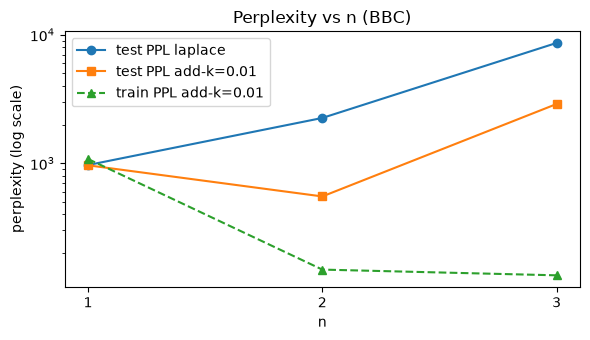

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for col, style in [("test PPL laplace", "o-"), (f"test PPL add-k={K}", "s-"), (f"train PPL add-k={K}", "^--")]:
    ax.plot(ppl.index, ppl[col], style, label=col)
ax.set_xticks([1, 2, 3]); ax.set_xlabel("n"); ax.set_ylabel("perplexity (log scale)")
ax.set_yscale("log"); ax.legend(); ax.set_title("Perplexity vs n (BBC)")
plt.tight_layout(); plt.show()

**Why bigram beats unigram:** one word of context sharply narrows the next word
(after "prime", "minister" dominates), so held-out text is less surprising.

**Why trigram can lose:** (and why, with Laplace, even the bigram loses to the unigram) most test trigrams never occurred in training (see the "unseen" column),
so the trigram model often falls back on smoothed pseudo-counts that know nothing about the words.
Its *training* perplexity keeps falling (it memorises), while *test* perplexity does not improve:
classic overfitting from sparsity. The fix is more data, or backoff/interpolation (Kneser–Ney),
which falls back to the bigram when the trigram is unseen. That is outside this lab's scope.
Without smoothing, test perplexity is infinite for n ≥ 2. The unigram is finite only because
`<UNK>` covers every unseen word.

## Text generation (Module V link)
Each sentence is sampled word by word from the counts after the current history
(`NGramLM.generate`, seeds 0–4).

In [9]:
generated = {n: [models[(n, "addk")].generate(max_words=25, seed=s) for s in range(5)] for n in [1, 2, 3]}
for n, sents in generated.items():
    print(f"--- {n}-gram")
    for s in sents:
        print("  ", s)

--- 1-gram
   secondary went end and government black building there it south broadband were but june spend with russian mondays inherit device be votes czech talking into
   a sold society and they go talks sport the to tv we studying will last me
   alerts exchange the the tv fails inquiry not network 37 individual in we been intend inflationary undeniable news over and the to which mr are
   is news number off despite the to fastest and is aguas six manager it used a 7 content seems death march the morning money said
   is of that in the that club's subject post
--- 2-gram
   russian authorities in the third cap record for me as orange film clips few hot favourite show it's always look at liverpool back lord lord
   the brainchild of the political and arsenal go on the music market expectations and she trains nothing he receives a very verge of 3 and
   read fun
   but i would quit his own father merrin made a filing
   but the valleys
--- 3-gram
   russian authorities to identify t

Unigram output is a word salad of common words; bigrams give locally plausible pairs; trigrams
read almost fluently but often copy long stretches of training sentences (little data per history).

In [10]:
save_results("ngram", {
    "dataset": "bbc", "n_train_sentences": len(train_sents), "n_test_sentences": len(test_sents),
    "vocab_size": len(base.vocab), "addk_k": K,
    "perplexity": ppl.reset_index().to_dict("records"),
    "sentence_logprob": logprob_table.reset_index().to_dict("records"),
    "probe_sentences": probe,
    "generated": {str(n): s for n, s in generated.items()},
})

saved results/ngram.json


PosixPath('/Users/mihirmandavia/nlp-news/results/ngram.json')

## Viva notes
**Q1. Why do we need smoothing?**
With MLE, any n-gram not seen in training has probability 0, so one unseen word pair makes the whole
sentence probability 0 and perplexity infinite (see the "none" columns). Add-k gives every word a
pseudo-count k, so nothing is impossible. Laplace (k=1) over-smooths when V is large.

**Q2. Why can bigram perplexity beat unigram, while trigram loses?**
More context makes predictions sharper, so bigram < unigram. But trigram histories are sparse: most
test trigrams were never seen, so the model relies on uninformed smoothing mass. Its training
perplexity drops (memorising) while test perplexity does not: overfitting caused by data sparsity.

**Q3. What is perplexity?**
exp(−(1/N) Σ log P(wi | history)) over all N predicted tokens (we count `</s>`). It is the effective
number of equally likely choices the model faces per word. It is only comparable between models
that share the same vocabulary and test set.